In [195]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import plotly.express as px
import seaborn as sns
import folium as fs
import numpy as np

In [2]:
df=pd.read_csv("Dataset .csv")

In [136]:
df

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes,Cluster
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Yes,No,No,No,3,4.8,Dark Green,5,314,0
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Yes,No,No,No,3,4.5,Dark Green,5,591,0
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Yes,No,No,No,4,4.4,Green,4,270,0
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,No,No,No,No,4,4.9,Dark Green,5,365,0
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Yes,No,No,No,4,4.8,Dark Green,5,229,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9546,5915730,Naml۱ Gurme,208,stanbul,"Kemanke Karamustafa Paa Mahallesi, R۱ht۱m Cadd...",Karak_y,"Karak_y, stanbul",28.977392,41.022793,Turkish,...,No,No,No,No,3,4.1,Green,4,788,4
9547,5908749,Ceviz Aac۱,208,stanbul,"Kouyolu Mahallesi, Muhittin st_nda Caddesi, No...",Kouyolu,"Kouyolu, stanbul",29.041297,41.009847,"World Cuisine, Patisserie, Cafe",...,No,No,No,No,3,4.2,Green,4,1034,4
9548,5915807,Huqqa,208,stanbul,"Kuru_eme Mahallesi, Muallim Naci Caddesi, No 5...",Kuru_eme,"Kuru_eme, stanbul",29.034640,41.055817,"Italian, World Cuisine",...,No,No,No,No,4,3.7,Yellow,3,661,4
9549,5916112,Ak Kahve,208,stanbul,"Kuru_eme Mahallesi, Muallim Naci Caddesi, No 6...",Kuru_eme,"Kuru_eme, stanbul",29.036019,41.057979,Restaurant Cafe,...,No,No,No,No,4,4.0,Green,4,901,4


In [23]:
df.isnull().sum()

Restaurant ID           0
Restaurant Name         0
Country Code            0
City                    0
Address                 0
Locality                0
Locality Verbose        0
Longitude               0
Latitude                0
Cuisines                0
Average Cost for two    0
Currency                0
Has Table booking       0
Has Online delivery     0
Is delivering now       0
Switch to order menu    0
Price range             0
Aggregate rating        0
Rating color            0
Rating text             0
Votes                   0
dtype: int64

In [5]:
df['Restaurant Name'] = df['Restaurant Name'].str.replace("�","",regex=False)

In [6]:
df['City'] = df['City'].str.replace("�","",regex=False)

In [7]:
df['Address'] = df['Address'].str.replace("�","",regex=False)

In [8]:
df['Locality'] = df['Locality'].str.replace("�","",regex=False)

In [9]:
df['Locality Verbose'] = df['Locality Verbose'].str.replace("�","",regex=False)

In [10]:
df.dropna(inplace=True)

LEVEL 1 TASK 1

In [11]:
df['Cuisines'].head(3)

0          French, Japanese, Desserts
1                            Japanese
2    Seafood, Asian, Filipino, Indian
Name: Cuisines, dtype: object

In [12]:
f=df['Cuisines'].value_counts().head(3)

In [13]:
total_restaurants = len(df)
p=(f/total_restaurants)*100
print("Percentage of Top Cuisines:", p)

Percentage of Top Cuisines: Cuisines
North Indian             9.809264
North Indian, Chinese    5.355271
Chinese                  3.709914
Name: count, dtype: float64


TASK2

In [14]:
df['City'].value_counts().head(1)

City
New Delhi    5473
Name: count, dtype: int64

In [15]:
df.groupby('City')['Aggregate rating'].mean()

City
Abu Dhabi          4.300000
Agra               3.965000
Ahmedabad          4.161905
Albany             3.552941
Allahabad          3.395000
                     ...   
Weirton            3.900000
Wellington City    4.250000
Winchester Bay     3.200000
Yorkton            3.300000
stanbul            4.292857
Name: Aggregate rating, Length: 140, dtype: float64

In [16]:
df.groupby('City')['Aggregate rating'].mean().head(1)

City
Abu Dhabi    4.3
Name: Aggregate rating, dtype: float64

Task 3

Text(0, 0.5, 'Number of Restaurants')

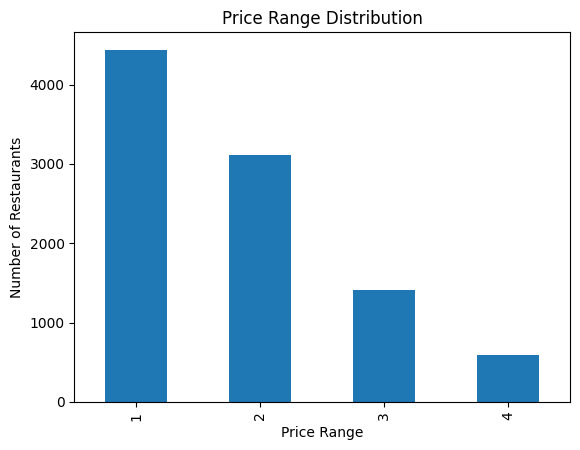

In [17]:
df['Price range'].value_counts().plot(kind='bar')
plt.title("Price Range Distribution")
plt.xlabel("Price Range")
plt.ylabel("Number of Restaurants")

In [18]:
x=df['Price range'].value_counts()
y=x.sum()
p=(x/y)*100
p

Price range
1    46.510166
2    32.624188
3    14.724376
4     6.141270
Name: count, dtype: float64

Task 4

In [19]:
a=df['Has Online delivery'].value_counts()
b=(a/9542)*100

In [20]:
b

Has Online delivery
No     74.313561
Yes    25.686439
Name: count, dtype: float64

Text(0, 0.5, 'Aggregate rating')

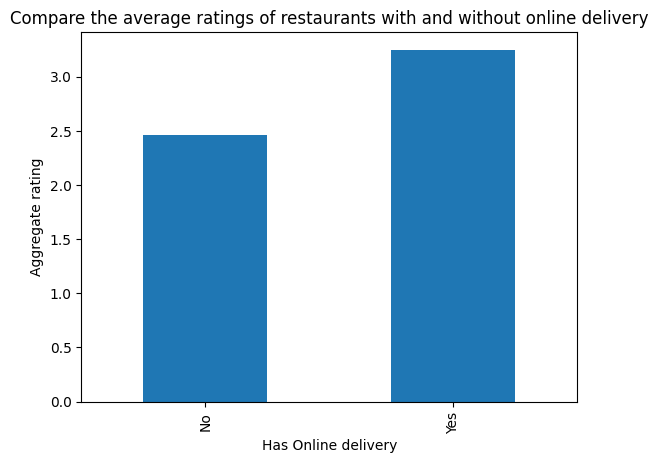

In [21]:
df.groupby('Has Online delivery')['Aggregate rating'].mean().plot(kind='bar')
plt.title("Compare the average ratings of restaurants with and without online delivery")
plt.xlabel("Has Online delivery")
plt.ylabel("Aggregate rating")